# Model C — the 6-1 standoff check and the C1 gap table (Oct 31, 2026) — descriptive only

**Spec (as given):**

> TASK: (1) the 6-1 standoff check, (2) the C1 gap table. Descriptive only. G-train only for
> human data. Never load Ring/CT. No edits to existing src/slider files (new helpers in a new
> file). No model changes.
>
> PART 1 - who breaks a standoff on Full?
> Data: G-train Full rounds (Full CL, Full CC), bot-free runs only, human seats.
> - Standoff = all 7 players at a wall (|s| = 1; old CL |k| = 10), split k vs 7-k with
>   k = 1 (6-1) or k = 2 (5-2), lasting >= 0.5 s.
> - First try = the first step off a wall by ANY player after the standoff starts (the first
>   step of an m = 2 reversal or a probe).
> - For each standoff record: the split; who made the first try (minority or majority); the
>   time from standoff start to that try; whether it was kept (reversal) or undone (probe);
>   which player arrived at its wall last before the standoff started, and whether that was
>   the minority player; and the round outcome (consensus or not).
> Report per interface and pooled, with group-bootstrap 95% CIs (1,000, stratified,
> seed 573):
>   a) number of standoffs and groups;
>   b) share of first tries by the minority, vs chance (1/7 for 6-1, 2/7 for 5-2);
>   c) TRY RATE RATIO = (minority tries per minority player-second at the wall) /
>      (majority tries per majority player-second), over the whole standoff;
>   d) P(kept) for minority vs majority tries;
>   e) share of standoffs where the last arriver was the minority player, and the minority
>      first-try share split by that;
>   f) the same (b, c) for the human-like baseline expected under C1 and under C2 as
>      designed: C1 = equal try rates (ratio 1); C2 = ratio 1 with keep 0.88 / 0.73.
>      Arithmetic only, no simulation.
> Table: results/tables/pC_standoffs.csv. Figure: minority first-try share with CIs vs the
> chance line, per split (results/figures/pC_standoffs.png).
>
> PART 2 - C1 gap table and the 10a mismatch
> - From p24_checks.csv: add C1 to pB1_gaps.csv (gap in CI half-widths, direction high/low,
>   change vs L1). Print the targets 1-4 rows for L1, B1 and C1.
> - 10a: explain why C1's 10a misses although durations were drawn from humans. Simulate C1
>   with 5 replicates (seed 7001, the L5 design). Per cell, compare human vs C1:
>     the 10a median;
>     the median wall-to-wall trip duration;
>     the median end-band-to-end-band crossing time (the 10a definition).
>   State which definitional difference explains the gap.
> - Do not change C1.
>
> Notebook: notebooks/path1/pC_checks.ipynb (spec cell first, short cells, a 2-3 line "how to
> read it" under each table and figure). Execute, add a README line, commit. Report both
> parts. Then stop.

## Choices

- **Data (part 1).** `load_runs("behavior", keep_bot=False, keep_incomplete=False)`: G-train only, bot-free, with an end marker (so the outcome is known; this drops 3 CC Full rounds), no whole-second files. Full rounds only, all 7 seats.
- **Positions.** k = round(10 s), sign-corrected, with the t = 0, k = 0 row first. At the wall = |k| = 10 (old CL: |s| >= 0.95, as the spec says).
- **Standoff start.** A row where all 7 seats are at a wall with a 6-1 or 5-2 split, and the row before is not the same configuration. The all-at-wall stretch from it must last >= 0.5 s, up to the first row with a seat off its wall or the round end.
- **Try.** The first step of an m = 2 event (`detect_events`) by a seat on its standoff wall: kept = reversal, undone = probe. The first try is the try on the first such row. A row with tries from both sides would be a "tie" (none occurred). By construction, the time to the first try equals the stretch, so it is >= 0.5 s.
- **"Over the whole standoff" (c).** The standoff runs from its start to its break or the round end. The break is the first reversal away from a seat's standoff wall; every break here was a kept try from the wall. Tries are every try in (start, break]. The exposure is each seat's time at its own wall over the same span, so time off the wall during a probe is not exposure.
- **Last arriver.** The seat(s) that reached their wall on the start row. NaN if seats of both sides did so (none occurred).
- **(d)** is given for the first tries and for all tries in the standoff. Unresolved events (the round ends first) are left out (none occurred).
- **Bootstrap.** 1,000 resamples of the log files, drawn with replacement within dataset (CL, CC), `rng(573)` per cell. Every cell is one interface (lab v09 and old CL are CL; cc is CC), or "pooled". A statistic with no cases in a resample is left out of that resample's CI.
- **(f) Baselines** (arithmetic): every seat at its wall tries at the same rate, so first_min_share = k/7 and the rate ratio = 1 under both C1 and C2. Extra line: break_min_share = the minority's share of the kept tries = k p_min / (k p_min + (7 - k) p_maj). For C1, p = 1. For C2, p_min = 0.88 and p_maj = 0.73, read as minority / majority (the order given; the human kept shares below are close to it).
- **Part 2.** p24_checks.csv holds the R = 200 C1 run (seed 7001), which the user ran on Oct 31 (`p24_reps_C1.parquet`). Its human values are the check targets (train + val, read from the CSV, not recomputed). The 10a diagnosis uses G-train human runs (`load_runs("behavior", keep_bot=False, keep_incomplete=False)`, as L5 but train only) and C1 on the L5 design: `design.design("L5")`, R = 5, `simulate_design(..., seed=7001)`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from slider import config, design, motion, standoffs
from slider import slider_logs as sl

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 120)
pd.set_option("display.width", 220)

runs, table = sl.load_runs("behavior", keep_bot=False, keep_incomplete=False)     # G-train: no G-val, Ring or CT
assert set(table["role"]) == {"train"}
table[table["topology"] == "Full"].groupby("dataset").agg(rounds=("file", "size"), groups=("file", "nunique"))

,rounds,groups
dataset,,
CC,31,14
CL,33,11


# Part 1 — who breaks a standoff on Full?

In [2]:
d = standoffs.standoff_table(runs, table)
print(d.groupby(["split", "interface"]).agg(standoffs=("file", "size"), groups=("file", "nunique"),
      first_by_minority=("first_by", lambda x: (x == "minority").sum()), ties=("first_by", lambda x: (x == "tie").sum()),
      no_try=("first_by", lambda x: (x == "none").sum()), consensus=("consensus", "mean")).round(2))
d[["file", "wave", "interface", "split", "start", "first_by", "first_time", "first_kept", "last_minority",
   "consensus", "tries_min", "tries_maj", "expo_min", "expo_maj"]].head(10).round(2)

                 standoffs  groups  first_by_minority  ties  no_try  consensus
split interface                                                               
5-2   cc                19       7                  6     0       0       0.63
      lab_v09            6       3                  2     0       0       1.00
6-1   cc                48      10                  5     0       0       0.88
      lab_v09           15       6                  3     0       0       0.87
      old_cl             7       1                  1     0       0       1.00


,file,wave,interface,split,start,first_by,first_time,first_kept,last_minority,consensus,tries_min,tries_maj,expo_min,expo_maj
0,log_Tue Sep 20 142130 EDT 2016.txt,3,old_cl,6-1,25.81,majority,0.70,1.0,1.0,1,0,1,0.70,4.20
1,log_Tue Sep 20 142130 EDT 2016.txt,5,old_cl,6-1,161.79,majority,20.00,1.0,0.0,1,0,1,20.00,120.00
2,log_Tue Sep 20 142130 EDT 2016.txt,5,old_cl,6-1,183.19,minority,4.30,1.0,0.0,1,1,0,4.30,25.80
3,log_Tue Sep 20 142130 EDT 2016.txt,7,old_cl,6-1,65.69,majority,8.70,1.0,0.0,1,0,1,8.70,52.20
4,log_Tue Sep 20 142130 EDT 2016.txt,7,old_cl,6-1,77.78,majority,6.81,0.0,0.0,1,0,2,14.11,84.36
5,log_Tue Sep 20 142130 EDT 2016.txt,7,old_cl,6-1,93.69,majority,3.69,1.0,0.0,1,0,1,3.69,22.14
6,log_Tue Sep 20 142130 EDT 2016.txt,7,old_cl,6-1,131.28,majority,4.90,0.0,0.0,1,1,1,6.51,38.06
7,log_v09_Fri Oct 07 162937 EDT 2016.txt,7,lab_v09,6-1,89.42,majority,1.80,1.0,0.0,1,0,1,1.80,10.80
8,log_v09_Fri Oct 07 162937 EDT 2016.txt,7,lab_v09,6-1,92.72,majority,1.90,0.0,0.0,1,0,2,2.30,13.40
9,log_v09_Fri Oct 07 162937 EDT 2016.txt,7,lab_v09,6-1,127.02,majority,6.70,1.0,0.0,1,0,1,6.70,40.20


**How to read it.** One row per standoff: the split, who made the first try and how long after the start, whether it was kept (1 = reversal, 0 = probe), whether the last arriver was the minority, and the round outcome. The top table counts standoffs and groups per split and interface. No try was ever a tie, and only one standoff ran to the round end with no try.

In [3]:
cells = [(f"{name}|{split}", rows[rows["split"] == split])
         for split in ["6-1", "5-2"] for name, rows in motion.by_interface(d)]
cells = [(c.replace("shared", "pooled"), rows) for c, rows in cells if len(rows)]
b = standoffs.boot_cells(d, cells, n_boot=1000, seed=config.SEED)
b[["interface", "split"]] = b["cell"].str.split("|", expand=True)
base = {split: standoffs.baselines(k) for k, split in standoffs.SPLITS.items()}
for model in ["C1", "C2"]:
    b[model] = [base[sp][model].get(s, np.nan) for sp, s in zip(b["split"], b["stat"])]
b = b[["interface", "split", "stat", "value", "ci_lo", "ci_hi", "C1", "C2"]]
b.to_csv(config.TABLES / "pC_standoffs.csv", index=False)
show = ["standoffs", "groups", "first_min_share", "rate_ratio", "kept_first_min", "kept_first_maj", "kept_all_min",
        "kept_all_maj", "break_min_share", "last_min_share", "first_min_share_last_min", "first_min_share_last_maj",
        "first_time_median"]
fmt = lambda r: (f"{r.value:.0f}" if np.isnan(r.ci_lo) else f"{r.value:.2f} [{r.ci_lo:.2f}, {r.ci_hi:.2f}]")
wide = b.assign(cell=b["interface"] + " " + b["split"], text=[fmt(r) for r in b.itertuples()])
wide = wide.pivot(index="stat", columns="cell", values="text").loc[show]
order = [f"{i} {s}" for s in ["6-1", "5-2"] for i in motion.INTERFACES + ["pooled"]]
wide[[c for c in order if c in wide.columns]]

cell,lab_v09 6-1,old_cl 6-1,cc 6-1,pooled 6-1,lab_v09 5-2,cc 5-2,pooled 5-2
stat,,,,,,,
standoffs,15,7,48,70,6,19,25
groups,6,1,10,17,3,7,10
first_min_share,"0.20 [0.06, 0.44]","0.14 [0.14, 0.14]","0.10 [0.02, 0.20]","0.13 [0.06, 0.20]","0.33 [0.00, 1.00]","0.32 [0.13, 0.47]","0.32 [0.18, 0.48]"
rate_ratio,"1.48 [0.62, 2.97]","1.71 [1.71, 1.71]","1.03 [0.37, 1.99]","1.18 [0.65, 1.85]","1.86 [0.82, nan]","0.93 [0.36, 1.94]","1.12 [0.64, 2.11]"
kept_first_min,"1.00 [1.00, 1.00]","1.00 [1.00, 1.00]","0.60 [0.20, 1.00]","0.78 [0.55, 1.00]","1.00 [1.00, 1.00]","1.00 [1.00, 1.00]","1.00 [1.00, 1.00]"
kept_first_maj,"0.42 [0.14, 0.75]","0.67 [0.67, 0.67]","0.60 [0.50, 0.73]","0.57 [0.48, 0.67]","0.75 [0.67, 1.00]","0.77 [0.62, 1.00]","0.76 [0.64, 0.92]"
kept_all_min,"1.00 [1.00, 1.00]","1.00 [1.00, 1.00]","0.64 [0.40, 1.00]","0.78 [0.60, 1.00]","1.00 [1.00, 1.00]","1.00 [1.00, 1.00]","1.00 [1.00, 1.00]"
kept_all_maj,"0.45 [0.20, 0.69]","0.71 [0.71, 0.71]","0.64 [0.57, 0.75]","0.60 [0.53, 0.69]","0.75 [0.67, 1.00]","0.81 [0.73, 1.00]","0.80 [0.72, 0.92]"
break_min_share,"0.36 [0.18, 0.63]","0.29 [0.29, 0.29]","0.15 [0.05, 0.26]","0.20 [0.11, 0.29]","0.50 [0.33, 1.00]","0.32 [0.13, 0.47]","0.36 [0.25, 0.50]"


In [4]:
b[b["stat"].isin(["first_min_share", "rate_ratio", "kept_all_min", "kept_all_maj", "break_min_share"])
  & (b["interface"] == "pooled")].round(3)

,interface,split,stat,value,ci_lo,ci_hi,C1,C2
41,pooled,6-1,first_min_share,0.129,0.059,0.200,0.143,0.143
42,pooled,6-1,rate_ratio,1.180,0.648,1.852,1.000,1.000
45,pooled,6-1,kept_all_min,0.778,0.600,1.000,1.000,0.880
46,pooled,6-1,kept_all_maj,0.604,0.533,0.690,1.000,0.730
47,pooled,6-1,break_min_share,0.203,0.115,0.292,0.143,0.167
80,pooled,5-2,first_min_share,0.320,0.176,0.476,0.286,0.286
81,pooled,5-2,rate_ratio,1.116,0.641,2.111,1.000,1.000
84,pooled,5-2,kept_all_min,1.000,1.000,1.000,1.000,0.880
85,pooled,5-2,kept_all_maj,0.800,0.720,0.923,1.000,0.730
86,pooled,5-2,break_min_share,0.360,0.250,0.500,0.286,0.325


**How to read it.** Each cell shows value [95% CI]. (a) is standoffs and groups. (b) is `first_min_share`: chance is 1/7 = 0.14 for 6-1 and 2/7 = 0.29 for 5-2. (c) is `rate_ratio`, the minority's tries per second at the wall over the majority's: 1 means equal rates. (d) is `kept_*` (first tries, all tries). (e) is `last_min_share` and the first-try share split by it. `break_min_share` is who made the standoff's break. The second table puts the pooled values next to the C1 and C2 baselines of (f). Groups are few, so the CIs are wide. Old CL is one group (its CI is a single point) and has no 5-2. A nan CI bound is infinite: some resamples had no majority tries.

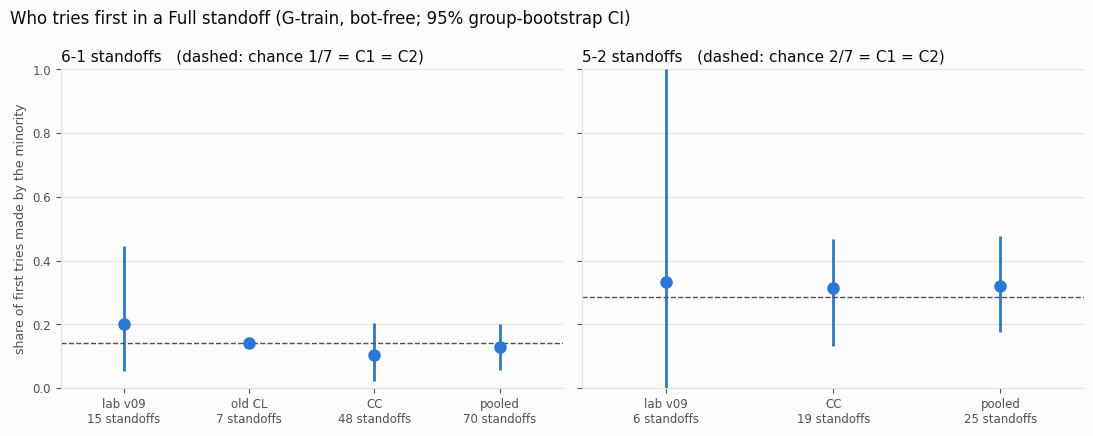

In [5]:
SURFACE, INK, INK_2, GRID, MARK = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df", "#2a78d6"
NAMES = {"lab_v09": "lab v09", "old_cl": "old CL", "cc": "CC", "pooled": "pooled"}
f = b[b["stat"] == "first_min_share"]
n = b[b["stat"] == "standoffs"].set_index(["interface", "split"])["value"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), facecolor=SURFACE, sharey=True)
for ax, (k, split) in zip(axes, standoffs.SPLITS.items()):
    x = f[f["split"] == split].set_index("interface").reindex([i for i in NAMES if i in set(f.loc[f["split"] == split, "interface"])])
    pos = np.arange(len(x))
    ax.errorbar(pos, x["value"], yerr=[x["value"] - x["ci_lo"], x["ci_hi"] - x["value"]], fmt="o", color=MARK,
                markersize=8, elinewidth=2, capsize=0)
    ax.axhline(k / 7, color=INK_2, linewidth=1, linestyle="--")
    ax.set_xticks(pos, [f"{NAMES[i]}\n{int(n[(i, split)])} standoffs" for i in x.index])
    ax.set_xlim(-0.5, len(x) - 0.5)
    ax.set_ylim(0, 1)
    ax.set_title(f"{split} standoffs   (dashed: chance {k}/7 = C1 = C2)", loc="left", fontsize=11, color=INK)
    ax.set_facecolor(SURFACE)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=INK_2, labelsize=8.5)
axes[0].set_ylabel("share of first tries made by the minority", color=INK_2, fontsize=9)
fig.suptitle("Who tries first in a Full standoff (G-train, bot-free; 95% group-bootstrap CI)", x=0.01, ha="left",
             fontsize=12, color=INK)
fig.tight_layout()
fig.savefig(config.FIGURES / "pC_standoffs.png", dpi=150, facecolor=SURFACE)
plt.show()

**How to read it.** Each dot is the share of standoffs in which a minority seat made the first try, with its 95% CI. The dashed line is chance (k/7). Chance is also the C1 and C2 baseline, since both have equal try rates. The old CL dot is one group. A dot above the line means minority seats try first more often than their numbers predict.

# Part 2 — the C1 gap table and the 10a mismatch

In [6]:
checks = pd.read_csv(config.P24_CHECKS)
key = ["target", "stat", "topology", "dataset"]
gaps = pd.read_csv(config.PB1_GAPS, float_precision="round_trip")
gaps = gaps.drop(columns=[c for c in gaps.columns if "C1" in c])                # a re-run starts from L1, final, B1
c1 = checks[checks["preset"] == "C1"].set_index(key)
g = gaps.set_index(key)
assert np.allclose(c1.loc[g.index, "human"], g["human"])                # the same human targets
g["gap_C1"] = (c1.loc[g.index, "sim_mean"] - g["human"]) / g["half_width"]
g["direction_C1"] = np.where(g["gap_C1"] > 0, "high", "low")
g["verdict_C1"] = c1.loc[g.index, "verdict"]
g["C1_minus_L1"] = g["gap_C1"] - g["gap_L1"]
gaps = g.reset_index()
gaps.to_csv(config.PB1_GAPS, index=False)
cols = key + ["human", "half_width", "gap_L1", "verdict_L1", "gap_B1", "verdict_B1", "gap_C1", "direction_C1",
              "verdict_C1", "C1_minus_L1"]
gaps.loc[gaps["target"].between(1, 4), cols].round(2)

,target,stat,topology,dataset,human,half_width,gap_L1,verdict_L1,gap_B1,verdict_B1,gap_C1,direction_C1,verdict_C1,C1_minus_L1
0,1,success_rate_pct,Full,CC,97.22,4.55,-8.74,miss,-8.79,miss,-8.13,low,miss,0.61
1,1,success_rate_pct,Full,CL,82.54,11.11,-3.80,miss,-3.96,miss,-4.09,low,miss,-0.29
2,1,success_rate_pct,Hierarchy,CC,92.50,7.89,-1.15,miss,-1.17,miss,-0.77,low,pass,0.37
3,1,success_rate_pct,Hierarchy,CL,95.08,5.26,-6.08,miss,-6.18,miss,-5.46,low,miss,0.63
4,1,success_rate_pct,Hierarchy,EL,94.12,5.88,-1.25,miss,-1.13,miss,-1.10,low,miss,0.16
5,1,success_rate_pct,Star,CC,100.00,4.51,-0.36,pass,-0.34,pass,-0.29,low,pass,0.07
6,2,consensus_time_km_median_s,Full,CC,45.99,13.62,7.05,miss,7.17,miss,6.73,high,miss,-0.33
7,2,consensus_time_km_median_s,Full,CL,89.19,23.80,8.83,miss,8.85,miss,8.85,high,miss,0.02
8,2,consensus_time_km_median_s,Hierarchy,CC,35.33,13.00,2.39,miss,2.31,miss,1.97,high,miss,-0.41
9,2,consensus_time_km_median_s,Hierarchy,CL,47.06,15.45,8.69,miss,9.03,miss,8.26,high,miss,-0.43


**How to read it.** These are targets 1-4 (C1's primary yardstick). Each `gap_*` is (model mean - human) / human-CI half-width: |gap| <= 1 is about a pass, and the verdict columns from `p24_checks.csv` decide. `direction_C1` says whether C1 sits above or below the humans, and `C1_minus_L1` is the change in half-widths. All three models are means over R = 200 replicates.

In [7]:
c = gaps[gaps["in_check_list"]]
summary = pd.DataFrame({p: {"passes": (c[f"verdict_{p}"] == "pass").sum(), "median |gap|": c[f"gap_{p}"].abs().median()}
                        for p in ["L1", "final", "B1", "C1"]}).T
by_target = c.assign(closer=c["gap_C1"].abs() < c["gap_L1"].abs()).groupby("target").agg(
    cells=("closer", "size"), C1_pass=("verdict_C1", lambda v: (v == "pass").sum()),
    L1_pass=("verdict_L1", lambda v: (v == "pass").sum()), C1_closer_than_L1=("closer", "sum"),
    C1_high=("direction_C1", lambda v: (v == "high").sum()))
display(summary.round(2))
by_target

,passes,median |gap|
L1,17.0,1.80
final,16.0,1.86
B1,17.0,1.76
C1,20.0,1.20


,cells,C1_pass,L1_pass,C1_closer_than_L1,C1_high
target,,,,,
1,6,2,1,5,0
2,6,0,0,4,6
3,3,3,3,1,0
4,6,4,6,2,5
5,2,0,0,0,0
6,6,4,3,4,2
7,6,1,1,5,6
8,6,5,2,5,0
9,6,0,0,5,0


**How to read it.** The top table gives passes and the median |gap| over the 53 check statistics. The bottom one, per target, gives cells, passes for C1 and L1, the cells where C1 is closer to the humans than L1, and the cells where C1 is above the humans. All of this is descriptive: C1 is EXPLORATORY and decides nothing.

## 10a: why C1 misses although its trips are drawn from humans

Five crossing times per cell (topology x dataset), human seats, medians (s):
- `tenA`: the 10a statistic (`targets.crossing_values`): end band (|k| >= 9) to the opposite end band; complete, no jump; CC on the 0.1 s lab clock.
- `band_raw`: the same crossings on the raw rows.
- `wall_to_wall`: every arrived wall-to-wall trip. C1 draws these, pooled per interface over the topologies.
- `w2w_clean`: the wall-to-wall trips that hold exactly one 10a crossing, which completes (no turn back mid-way).
- `core_clean`: that crossing's band-to-band time; `lead_clean` / `tail_clean`: the rest of the clean trip (wall to band exit / band entry to wall).

Plus `clean_share`, the share of trips that are clean, and `lead_05_share`, the share of clean trips whose lead is 0.5 s within 10 ms. Humans: G-train. C1: R = 5 on the L5 design, seed 7001.

In [8]:
human = standoffs.crossing_times(runs)
d5 = design.design("L5")
sim_runs, _ = design.simulate_design(d5, "C1", R=5, seed=7001)
c1t = standoffs.crossing_times(sim_runs)
p24 = checks[(checks["stat"] == "crossing_time_median_s")].pivot_table(index=["topology", "dataset"], columns="preset",
                                                                        values="sim_mean")
hum24 = checks[(checks["stat"] == "crossing_time_median_s") & (checks["preset"] == "C1")].set_index(["topology", "dataset"])
cmp = pd.concat({"human": human, "C1": c1t}, axis=1).swaplevel(axis=1)
cols = ["tenA", "band_raw", "wall_to_wall", "w2w_clean", "core_clean", "lead_clean", "tail_clean", "clean_share",
        "lead_05_share"]
cmp = cmp[[(c, w) for c in cols for w in ["human", "C1"]]]
cmp[("p24 10a", "human (train+val)")] = hum24["human"]
cmp[("p24 10a", "C1 R=200")] = p24["C1"]
cmp.round(2)

tenA      band_raw       wall_to_wall       w2w_clean       core_clean       lead_clean       tail_clean       clean_share      lead_05_share                 p24 10a         
                  human   C1    human    C1        human    C1     human    C1      human    C1      human    C1      human    C1       human   C1         human    C1 human (train+val) C1 R=200
topology  dataset                                                                                                                                                                                
Full      CC       0.60  1.0     0.58  1.02         1.17  1.12      1.13  1.12       0.57  1.02        0.5  0.07       0.03  0.03        0.96  1.0          0.56  0.00               0.6     1.00
          CL       2.50  3.0     2.50  3.00         3.50  3.30      3.10  3.30       2.40  3.00        0.5  0.20       0.10  0.10        0.89  1.0          0.56  0.03               3.3     3.01
Hierarchy CC       0.60  1.0     0.57  1.02         1.11  1.12      1.11  1.12       0.56  1.02        0.5  0.07       0.03  0.03        0.98  1.0          0.48  0.00               0.6     1.01
          CL       1.70  3.4     1.70  3.40         2.30  3.90      2.30  3.90       1.70  3.40        0.5  0.25       0.10  0.20        0.96  1.0          0.61  0.02               1.8     3.53
          EL       1.71  2.4     1.71  2.40         2.40  2.70      2.39  2.70       1.71  2.40        0.5  0.20       0.10  0.10        0.96  1.0          0.48  0.03               1.8     2.39
Star      CC       0.60  1.0     0.57  1.02         1.12  1.12      1.11  1.12       0.57  1.02        0.5  0.07       0.03  0.03        0.96  1.0          0.48  0.00               0.6     1.01

In [9]:
ratio = pd.DataFrame({w: (t["tenA"] / t["wall_to_wall"]) for w, t in [("human", human), ("C1", c1t)]})
ratio["core / clean w2w, human"] = human["core_clean"] / human["w2w_clean"]
ratio["core / clean w2w, C1"] = c1t["core_clean"] / c1t["w2w_clean"]
ratio.columns = ["10a / wall-to-wall, human", "10a / wall-to-wall, C1"] + list(ratio.columns[2:])
ratio.round(2)

10a / wall-to-wall, human  10a / wall-to-wall, C1  core / clean w2w, human  core / clean w2w, C1
topology  dataset                                                                                                  
Full      CC                            0.51                    0.89                     0.50                  0.91
          CL                            0.71                    0.91                     0.77                  0.91
Hierarchy CC                            0.54                    0.89                     0.51                  0.91
          CL                            0.74                    0.87                     0.74                  0.87
          EL                            0.71                    0.89                     0.71                  0.89
Star      CC                            0.53                    0.89                     0.51                  0.91

**How to read it.** Medians in seconds; humans are G-train, C1 is R = 5 on the L5 design. The last two columns are the 10a values from `p24_checks.csv`: the human target (train + val) and C1's mean over R = 200. The ratio table gives the share of a trip that 10a measures.

**Which definitional difference explains the gap: the start of the clock.** A wall-to-wall trip starts at the first step off the wall. A 10a crossing starts at the first row outside the end band (|k| < 9), one step later. Human trips pause after that first step: in about half of the clean trips, the lead (wall to band exit) is 0.5 s within 10 ms, and the median lead is 0.5 s in every cell (a fixed delay after a first key press, likely the keyboard's auto-repeat; not checked).
- That pause sits inside the end band, so 10a leaves it out and the wall-to-wall trip keeps it. In CC, the human band-to-band time is only about half the clean trip (0.57 of 1.13 s).
- C1 draws the whole wall-to-wall duration, pause included, and spreads it evenly over every step. So its band-to-band part is about 0.9 of the trip (1.02 of 1.12 s), and its lead is a tick or two.
- Arithmetic check for CC: human 10a 0.57 s + 0.9 x 0.5 s ≈ 1.0 s, which is C1's 10a. In the CC cells, C1's wall-to-wall median matches the humans' (1.12 vs 1.11–1.17 s), and the whole 10a miss (0.6 vs 1.0 s, about 8 half-widths of the pinned ±0.05 s CI) comes from this.

**Other differences are small or not definitional.**
- The CC lab clock and the jump filter change little (`tenA` vs `band_raw`).
- Trips that turn back mid-way (not clean) are 2-11% of trips.
- In Hierarchy CL and EL, C1's wall-to-wall median itself is too long (3.9 vs 2.3 s and 2.7 vs 2.4 s). C1 draws from one pool per interface, pooled over topologies and lab round speeds, and its simulated trip mix differs from the human cell's. For example, old CL trips, with a median of 10.6 s, make up 26% of the L5 design's Hierarchy CL rounds but only 16 of the 352 G-train Hierarchy CL trips. This is a sampling difference in C1's pools, not a definitional one, and it was not diagnosed further.
- C1 is not changed.